# Compare average reward of the two agents across methods and node counts

Run the cells in order. Place this notebook **inside** `COMPARISON_WITH_OTHER_MODELS` (or in its parent folder). It discovers `.npz` archives such as `ha2c_training_results_45 nodes_lr_0_00001.npz`, `maa2c_v11_training_results_45.npz`, and `mappo_v11_training_results_45.npz` automatically, including newly added method types and node counts.

The per-episode average reward is **(Agent 1 reward + Agent 2 reward) / 2**; it is *not* a sum or an average over all episodes. The first processing cell saves each method/node series as an independent `.npz` for reuse. The next cell reads **only those processed files**. The last cell generates one figure per detected node count and saves PNGs at 600 DPI. No title is added to the figures.

*Note:* The original `.npz` files are not included with this notebook; run it in the folder containing your experiment results.

In [65]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Work when the notebook is inside the experiment folder or one level above it.
DATA_DIR = (Path('COMPARISON_WITH_OTHER_MODELS')
            if Path('COMPARISON_WITH_OTHER_MODELS').is_dir()
            else Path('.'))
PROCESSED_DIR = DATA_DIR / 'processed_average_rewards'
FIGURE_DIR = DATA_DIR / 'average_reward_figures'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# File formats supported:
# ha2c_training_results_45 nodes_lr_0_00001.npz
# maa2c_v11_training_results_45.npz
# mappo_v11_training_results_45.npz
# <new_method>_training_results_<node_number>[ nodes][...].npz
ARCHIVE_RE = re.compile(
    r'^(?P<method>.+?)_training_results[_ -]+'
    r'(?P<nodes>\d+)(?:[_ -]*nodes?)?'
    r'(?:[_ -]*lr[_ -]*[0-9_.]+)?\.npz$',
    re.IGNORECASE
)

def display_name(method):
    """Readable legend names; all unrecognized new methods remain supported."""
    canonical = re.sub(r'[_ -]*v\d+$', '', method, flags=re.IGNORECASE).lower()
    known = {'ha2c': 'Proposed', 'maa2c': 'MAA2C', 'mappo': 'MAPPO'}
    return known.get(canonical, method.replace('_', ' ').upper())

def reward_key(keys, agent):
    """Find only this agent's EPISODIC reward/return key; never use cost/loss."""
    key_by_normalized = {re.sub(r'[^a-z0-9]', '', k.lower()): k for k in keys}
    preferred = [
        f'agent{agent}reward', f'agent{agent}episodereward',
        f'agent{agent}avgreturn', f'agent{agent}return',
        f'avgreturn{agent}', f'episodereward{agent}',
        f'rewardagent{agent}', f'returnagent{agent}',
    ]
    for candidate in preferred:
        if candidate in key_by_normalized:
            return key_by_normalized[candidate]
    # If unconventional field names are used, stop rather than confusing
    # other metrics (such as actor/critic loss) with episodic rewards.
    raise KeyError(
        f'Cannot identify Agent {agent} reward. Available keys: {list(keys)}. '
        'Update reward_key() to match the actual saved reward field.'
    )

print('Input directory:', DATA_DIR.resolve())
print('Processed output:', PROCESSED_DIR.resolve())
print('Figure output:', FIGURE_DIR.resolve())

Input directory: /home/cci/Downloads/Latest/Revised/Revised_lr_variation/comparison_with_other_models
Processed output: /home/cci/Downloads/Latest/Revised/Revised_lr_variation/comparison_with_other_models/processed_average_rewards
Figure output: /home/cci/Downloads/Latest/Revised/Revised_lr_variation/comparison_with_other_models/average_reward_figures


## 1. Extract both agents’ rewards, calculate their per-episode average, and save reusable data

In [66]:
source_files = sorted(DATA_DIR.glob('*.npz')) 
 
if not source_files: 
    raise FileNotFoundError( 
        f'No source .npz files found in {DATA_DIR.resolve()}' 
    ) 
 
records = [] 
seen = {} 
 
for source in source_files: 
 
    # --------------------------------------------------------- 
    # Parse method name and number of nodes from filename 
    # --------------------------------------------------------- 
    match = ARCHIVE_RE.match(source.name) 
 
    if match is None: 
        print(f'Skipping unrecognized filename: {source.name}') 
        continue 
 
    method = match.group('method') 
    nodes = int(match.group('nodes')) 
 
    # ---------------------------------------------------------
    # Display / legend name
    # ---------------------------------------------------------
    if method.lower() == 'single_agent_a2c':
        legend_name = 'Single Agent A2C'
    else:
        legend_name = display_name(method)
 
    identity = (method.lower(), nodes) 
 
    if identity in seen: 
        raise ValueError( 
            f'Multiple files for method={method!r}, nodes={nodes}: ' 
            f'{seen[identity].name}, {source.name}. ' 
            'Keep one run per method/node in this comparison folder.' 
        ) 
 
    seen[identity] = source 
 
    # --------------------------------------------------------- 
    # Load source archive 
    # --------------------------------------------------------- 
    with np.load(source, allow_pickle=False) as archive: 
 
        # ===================================================== 
        # SINGLE-AGENT A2C 
        # ===================================================== 
        if source.name.lower().startswith('single_agent'): 
 
            if 'reward' not in archive.files: 
                raise KeyError( 
                    f'{source.name}: expected key "reward" for ' 
                    f'single-agent results. ' 
                    f'Available keys: {archive.files}' 
                ) 
 
            reward = np.asarray( 
                archive['reward'], 
                dtype=np.float64 
            ) 
 
            # Preserve original single-agent reward after averaging:
            #
            # average_reward = (agent1 + agent2) / 2
            #                = (2*reward + 0) / 2
            #                = reward
 
            agent1 = 2.0 * reward 
 
            agent2 = np.zeros_like( 
                reward, 
                dtype=np.float64 
            ) 
 
            k1 = 'reward' 
            k2 = '0' 
 
        # ===================================================== 
        # MULTI-AGENT METHODS 
        # ===================================================== 
        else: 
 
            k1 = reward_key( 
                archive.files, 
                1 
            ) 
 
            k2 = reward_key( 
                archive.files, 
                2 
            ) 
 
            agent1 = np.asarray( 
                archive[k1], 
                dtype=np.float64 
            ) 
 
            agent2 = np.asarray( 
                archive[k2], 
                dtype=np.float64 
            ) 
 
    # --------------------------------------------------------- 
    # Validate reward arrays 
    # --------------------------------------------------------- 
    if ( 
        agent1.ndim != 1 
        or agent2.ndim != 1 
        or agent1.size == 0 
        or agent1.shape != agent2.shape 
    ): 
        raise ValueError( 
            f'{source.name}: agent reward arrays must be nonempty ' 
            f'1-D arrays with equal length; ' 
            f'got {agent1.shape} and {agent2.shape}.' 
        ) 
 
    # --------------------------------------------------------- 
    # Check for NaN / Inf 
    # --------------------------------------------------------- 
    if not ( 
        np.isfinite(agent1).all() 
        and np.isfinite(agent2).all() 
    ): 
        raise ValueError( 
            f'{source.name}: reward arrays contain NaN/inf.' 
        ) 
 
    # --------------------------------------------------------- 
    # Compute average reward 
    # --------------------------------------------------------- 
    avg_reward = ( 
        agent1 + agent2 
    ) / 2.0 
 
    # --------------------------------------------------------- 
    # Output file path 
    # --------------------------------------------------------- 
    processed_path = ( 
        PROCESSED_DIR 
        / f'average_reward_{method.lower()}_{nodes}_nodes.npz' 
    ) 
 
    # --------------------------------------------------------- 
    # Save processed data 
    # --------------------------------------------------------- 
    np.savez_compressed( 
        processed_path, 
 
        method=np.asarray(method),

        # Save display/legend name also
        legend_name=np.asarray(legend_name),
 
        nodes=np.asarray( 
            nodes, 
            dtype=np.int64 
        ), 
 
        source_filename=np.asarray( 
            source.name 
        ), 
 
        episodes=np.arange( 
            1, 
            agent1.size + 1, 
            dtype=np.int64 
        ), 
 
        agent1_reward=agent1, 
 
        agent2_reward=agent2, 
 
        average_reward=avg_reward, 
    ) 
 
    # --------------------------------------------------------- 
    # Record summary information 
    # --------------------------------------------------------- 
    records.append( 
        ( 
            nodes, 
            method,
            legend_name,
            source.name, 
            processed_path.name, 
            agent1.size 
        ) 
    ) 
 
    # --------------------------------------------------------- 
    # Print processing information 
    # --------------------------------------------------------- 
    if source.name.lower().startswith('single_agent'): 
 
        print( 
            f'{nodes:>4} nodes | ' 
            f'{legend_name:<16} | ' 
            f'{agent1.size:>5} episodes | ' 
            f'reward -> ' 
            f'Agent1 = 2*reward, Agent2 = 0 -> ' 
            f'{processed_path.name}' 
        ) 
 
    else: 
 
        print( 
            f'{nodes:>4} nodes | ' 
            f'{legend_name:<16} | ' 
            f'{agent1.size:>5} episodes | ' 
            f'{k1} + {k2} -> ' 
            f'{processed_path.name}' 
        ) 
 
 
# ------------------------------------------------------------- 
# Make sure at least one archive was successfully processed 
# ------------------------------------------------------------- 
if not records: 
 
    raise FileNotFoundError( 
        'No recognized training-results archives found. ' 
        'Expected filenames like ' 
        "'ha2c_training_results_45 nodes_lr_0_00001.npz', " 
        "'maa2c_v11_training_results_45.npz', " 
        "'mappo_v11_training_results_45.npz', or " 
        "'single_agent_a2c_training_results_45.npz'." 
    ) 
 
 
# ------------------------------------------------------------- 
# Final summary 
# ------------------------------------------------------------- 
print( 
    f'\nSaved {len(records)} processed ' 
    f'method/node reward archives.' 
)

  45 nodes | DISCRETE MADDPG V11 STYLE |  2000 episodes | agent1_reward + agent2_reward -> average_reward_discrete_maddpg_v11_style_45_nodes.npz
  55 nodes | DISCRETE MADDPG V11 STYLE |  2000 episodes | agent1_reward + agent2_reward -> average_reward_discrete_maddpg_v11_style_55_nodes.npz
  65 nodes | DISCRETE MADDPG V11 STYLE |  2000 episodes | agent1_reward + agent2_reward -> average_reward_discrete_maddpg_v11_style_65_nodes.npz
  45 nodes | Proposed         |  2000 episodes | agent1_reward + agent2_reward -> average_reward_ha2c_45_nodes.npz
  55 nodes | Proposed         |  2000 episodes | agent1_reward + agent2_reward -> average_reward_ha2c_55_nodes.npz
  65 nodes | Proposed         |  2000 episodes | agent1_reward + agent2_reward -> average_reward_ha2c_65_nodes.npz
  45 nodes | MAA2C            |  2000 episodes | agent1_reward + agent2_reward -> average_reward_maa2c_v11_45_nodes.npz
  55 nodes | MAA2C            |  2000 episodes | agent1_reward + agent2_reward -> average_reward_maa

## 2. Reload the *saved* average-reward files (works even in a fresh kernel)

After Section 1 has run once, you can rerun this cell and the plotting cell without loading or averaging the original training archives again.

In [67]:
# Load ONLY reusable processed files; do not depend on `records` above.
processed_files = sorted(PROCESSED_DIR.glob('average_reward_*_nodes.npz'))
if not processed_files:
    raise FileNotFoundError(
        f'No processed average rewards in {PROCESSED_DIR.resolve()}. '
        'Run the extraction-and-save cell first.'
    )

reward_by_node = {}  # {node_count: {method_identifier: {'episodes': ..., 'average_reward': ...}}}
for path in processed_files:
    with np.load(path, allow_pickle=False) as archive:
        method = str(archive['method'].item())
        nodes = int(archive['nodes'].item())
        episodes = np.asarray(archive['episodes'], dtype=np.int64)
        values = np.asarray(archive['average_reward'], dtype=np.float64)

    if episodes.ndim != 1 or values.ndim != 1 or episodes.size == 0 or episodes.shape != values.shape:
        raise ValueError(f'Invalid saved reward/episode arrays in {path.name}')
    if not np.all(np.isfinite(values)):
        raise ValueError(f'Invalid reward values in {path.name}')

    if method in reward_by_node.setdefault(nodes, {}):
        raise ValueError(f'Duplicate processed reward data for {method}, {nodes} nodes')
    reward_by_node[nodes][method] = {'episodes': episodes, 'average_reward': values}

for nodes, method_data in sorted(reward_by_node.items()):
    print(f'{nodes} nodes: ' + ', '.join(
        f'{display_name(m)} ({len(arr["episodes"])} episodes)'
        for m, arr in sorted(method_data.items())
    ))

45 nodes: DISCRETE MADDPG V11 STYLE (2000 episodes), Proposed (2000 episodes), MAA2C (2000 episodes), MAPPO (2000 episodes), SINGLE AGENT A2C (2000 episodes)
55 nodes: DISCRETE MADDPG V11 STYLE (2000 episodes), Proposed (2000 episodes), MAA2C (2000 episodes), MAPPO (2000 episodes), SINGLE AGENT A2C (2000 episodes)
65 nodes: DISCRETE MADDPG V11 STYLE (2000 episodes), Proposed (2000 episodes), MAA2C (2000 episodes), MAPPO (2000 episodes), SINGLE AGENT A2C (2000 episodes)


## 3. Compare methods — one figure per node count, PNG only

For the currently shown 45-, 55-, and 65-node files this creates **three plots**, comparing Proposed (HA2C), MAA2C, and MAPPO. If a new model is added with those three node counts, it automatically appears as an additional curve in each figure. If a *new node count* is added, it automatically gets its own additional figure.

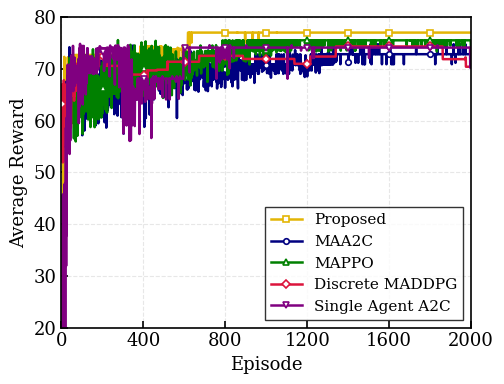

Saved: average_reward_figures/average_reward_methods_45_nodes.png


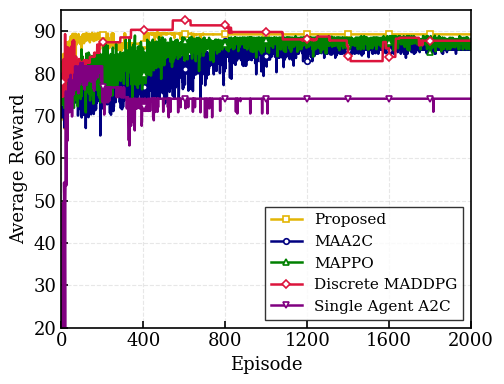

Saved: average_reward_figures/average_reward_methods_55_nodes.png


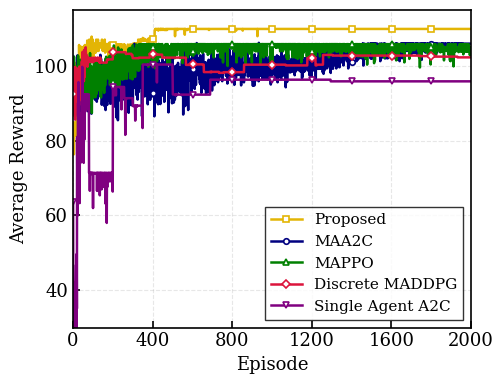

Saved: average_reward_figures/average_reward_methods_65_nodes.png

Saved 3 PNG figures in /home/cci/Downloads/Latest/Revised/Revised_lr_variation/comparison_with_other_models/average_reward_figures


In [72]:
plt.rcParams.update({
    'font.family': 'DejaVu Serif',
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
    'axes.linewidth': 1.2,
    'lines.linewidth': 2.0,
    'grid.linewidth': 0.8,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Match the colors/markers consistently across node counts.
PLOT_STYLES = {
    'ha2c':  {'color': '#E3B505', 'marker': 's'},
    'maa2c': {'color': 'navy',    'marker': 'o'},
    'mappo': {'color': 'green',   'marker': '^'},
}

EXTRA_STYLES = [
    {'color': 'crimson', 'marker': 'D'},
    {'color': 'purple',  'marker': 'v'},
    {'color': 'teal',    'marker': 'P'},
    {'color': 'black',   'marker': 'X'},
]


def canonical_method(method):
    return re.sub(
        r'[_ -]*v\d+$',
        '',
        method,
        flags=re.IGNORECASE
    ).lower()


all_methods = sorted({
    m
    for methods in reward_by_node.values()
    for m in methods
})

other_methods = sorted(
    {
        canonical_method(m)
        for m in all_methods
    } - set(PLOT_STYLES)
)

for index, name in enumerate(other_methods):
    PLOT_STYLES[name] = EXTRA_STYLES[
        index % len(EXTRA_STYLES)
    ]


# -------------------------------------------------------------
# Legend order
# -------------------------------------------------------------
priority = {
    'ha2c': 0,
    'maa2c': 1,
    'mappo': 2,
}


def model_sort_key(method):
    canonical = canonical_method(method)

    return (
        priority.get(canonical, 3),
        canonical,
        method
    )


# -------------------------------------------------------------
# Y-axis limits for each node count
# -------------------------------------------------------------
Y_LIMITS = {
    45: (20, 80),
    55: (20, 95),
    65: (30, 115),
}


saved_figures = []


for nodes in sorted(reward_by_node):

    fig, ax = plt.subplots(
        figsize=(5.2, 4)
    )

    max_episode = 0

    for method in sorted(
        reward_by_node[nodes],
        key=model_sort_key
    ):

        data = reward_by_node[nodes][method]

        x = data['episodes']
        y = data['average_reward']

        style = PLOT_STYLES[
            canonical_method(method)
        ]

        max_episode = max(
            max_episode,
            int(x.max())
        )

        # Approximately one marker every 200 episodes
        # when there are 2000 episodes.
        marker_interval = max(
            1,
            round(len(x) / 10)
        )

        # -----------------------------------------------------
        # Legend labels
        # -----------------------------------------------------
        normalized_method = (
            method
            .strip()
            .upper()
            .replace("_", " ")
        )

        if normalized_method == "DISCRETE MADDPG V11 STYLE":
            legend_label = "Discrete MADDPG"

        elif normalized_method == "SINGLE AGENT A2C":
            legend_label = "Single Agent A2C"

        else:
            legend_label = display_name(method)

        # -----------------------------------------------------
        # Plot
        # -----------------------------------------------------
        ax.plot(
            x,
            y,
            label=legend_label,
            color=style['color'],
            linestyle='-',
            linewidth=1.8,
            marker=style['marker'],
            markersize=4,
            markevery=marker_interval,
            markerfacecolor='white',
            markeredgewidth=1.2,
        )


    # ---------------------------------------------------------
    # Axis labels
    # ---------------------------------------------------------
    ax.set_xlabel('Episode')
    ax.set_ylabel('Average Reward')


    # ---------------------------------------------------------
    # X-axis
    # ---------------------------------------------------------
    ax.set_xlim(
        0,
        max(1, max_episode)
    )


    # ---------------------------------------------------------
    # Y-axis
    # ---------------------------------------------------------
    if nodes in Y_LIMITS:
        ax.set_ylim(
            Y_LIMITS[nodes]
        )
    else:
        # Fallback autoscaling for any other node count
        ax.relim()
        ax.autoscale_view(
            scalex=False,
            scaley=True
        )
        ax.margins(y=0.06)


    # ---------------------------------------------------------
    # Tick formatting
    # ---------------------------------------------------------
    ax.xaxis.set_major_locator(
        MaxNLocator(
            nbins=5,
            integer=True
        )
    )


    # ---------------------------------------------------------
    # Legend
    # ---------------------------------------------------------
    ax.legend(
        loc='lower right',
        frameon=True,
        edgecolor='black',
        fancybox=False
    )


    # ---------------------------------------------------------
    # Grid and ticks
    # ---------------------------------------------------------
    ax.grid(
        True,
        linestyle='--',
        alpha=0.3
    )

    ax.tick_params(
        axis='both',
        which='major',
        direction='in',
        length=5,
        width=1.2
    )


    fig.tight_layout()


    # ---------------------------------------------------------
    # Save figure
    # ---------------------------------------------------------
    figure_path = (
        FIGURE_DIR
        / f'average_reward_methods_{nodes}_nodes.png'
    )

    fig.savefig(
        figure_path,
        dpi=600,
        bbox_inches='tight'
    )

    saved_figures.append(
        figure_path
    )

    plt.show()

    plt.close(fig)

    print(
        f'Saved: {figure_path}'
    )


print(
    f'\nSaved {len(saved_figures)} PNG figures '
    f'in {FIGURE_DIR.resolve()}'
)